In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model,plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

<h1> Import Data and remove NANs

Text(0.5, 0.98, 'All Data')

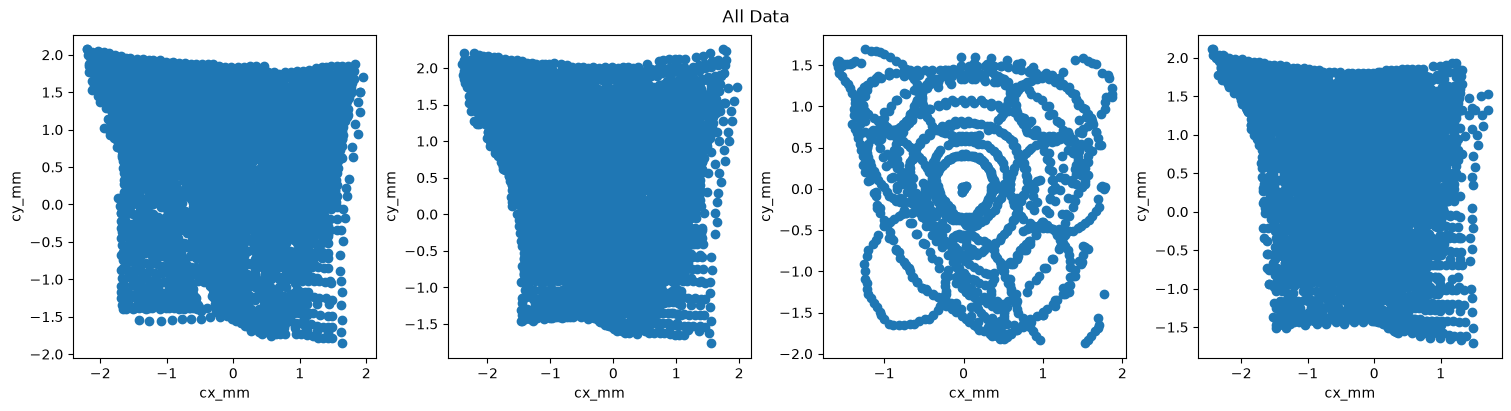

In [68]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [data_0, data_1, data_2, data_3]

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2> Add names?

In [54]:
data_0.Name = "data_0"
data_1.Name = "data_1"
data_2.Name = "data_2"
data_3.Name = "data_3"

<h2>Concatenate

In [72]:
all_data = pd.concat(data_list, ignore_index=True)

In [56]:
all_data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0.0,0.0,1.272000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1.0,1.0,2.699900,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2.0,0.0,23.035400,1.2,1.2,1.200032,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3.0,1.0,25.126699,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4.0,2.0,27.201900,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12654,4131.0,438.0,930.447327,0.8,1.0,0.799946,1.0,5120.0,-6107.0,987.0,...,74.0,6.0,92.0,-66.0,372.0,214.0,-54.0,-192.0,0.490909,1.745455
12655,4132.0,439.0,932.599792,0.9,1.0,0.900080,1.0,5120.0,-6551.0,1431.0,...,74.0,6.0,74.0,-66.0,354.0,214.0,-72.0,-192.0,0.654545,1.745455
12656,4133.0,440.0,934.675293,1.0,1.0,0.999989,1.0,5120.0,-6994.0,1874.0,...,74.0,6.0,56.0,-66.0,336.0,214.0,-90.0,-192.0,0.818182,1.745455
12657,4134.0,0.0,20.037100,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,222.0,6.0,212.0,82.0,492.0,362.0,66.0,-44.0,-0.600000,0.400000


<h2> Create StandardScalers based on all data

In [57]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

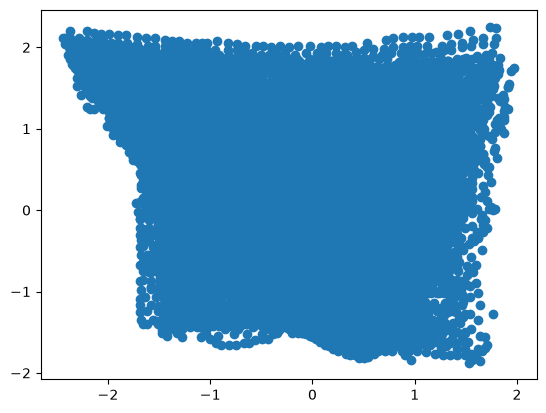

In [58]:
plt.scatter(all_data["cx_mm"], all_data["cy_mm"])

<h2>Scale all datasets

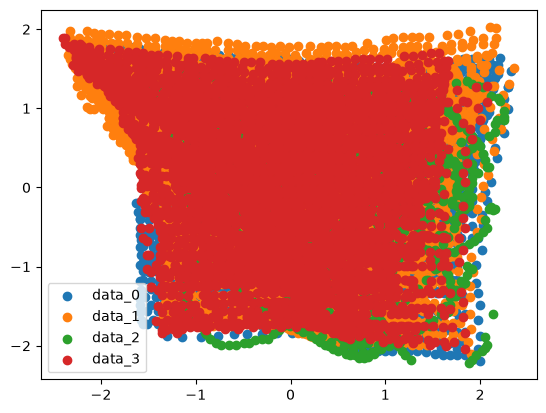

In [59]:
scaled = {}
for i, data in enumerate(data_list):
    scaled[f"X_scaled_{i}"] = scalerX.transform(data[["cx_mm", "cy_mm"]])
    scaled[f"y_scaled_{i}"] = scalerY.transform(data[["s0", "s1", "s2"]])
    plt.scatter(scaled[f"X_scaled_{i}"][:,0], scaled[f"X_scaled_{i}"][:,1], label=f"data_{i}")
    plt.legend()

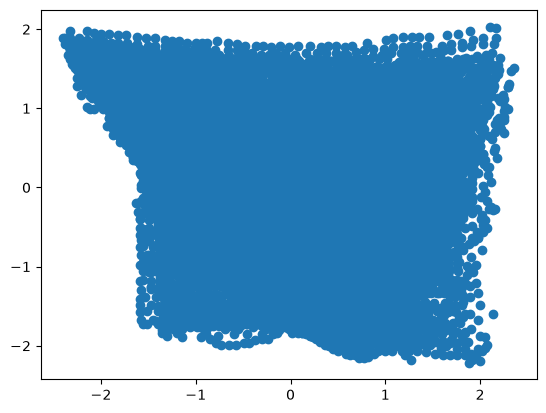

In [73]:
X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])
plt.scatter(X_scaled_all[:,0], X_scaled_all[:,1])

In [61]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

In [62]:
scaled

{'X_scaled_0': array([[ 0.23122713, -0.28630504],
        [ 0.23122713, -0.28630504],
        [ 2.3300793 ,  1.4717283 ],
        ...,
        [-1.377239  , -1.2214291 ],
        [-0.3376206 ,  0.08774462],
        [-0.3376206 ,  0.08774462]], shape=(3562, 2), dtype=float32),
 'y_scaled_0': array([[-7.7252276e-03,  9.5149828e-03, -1.7628012e-03],
        [-7.7252276e-03,  9.5149828e-03, -1.7628012e-03],
        [ 1.7483078e+00, -2.3955166e+00,  6.4014739e-01],
        ...,
        [-1.4710859e+00,  2.0136604e+00, -5.3664041e-01],
        [-7.7252276e-03,  9.5149828e-03, -1.7628012e-03],
        [-7.7252276e-03,  9.5149828e-03, -1.7628012e-03]],
       shape=(3562, 3), dtype=float32),
 'X_scaled_1': array([[ 0.24103485, -0.28630504],
        [ 0.2214194 , -0.28630504],
        [ 2.3595023 ,  1.5091332 ],
        ...,
        [-0.17088939,  0.18125704],
        [-0.17088939,  0.18125704],
        [-0.17088939,  0.18125704]], shape=(3967, 2), dtype=float32),
 'y_scaled_1': array([[-7.7252

In [65]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        restore_best_weights=True
    )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    callbacks=callbacks)
    print(patience)
    return history

Fold0, 0:
  Train: index=0 to 891 
  Test:  index=892 to 1781
1

Fold: 0 Results (scaled):
  Overall R2:  0.9101
  Weighted R2: 0.9039
Fold0, 1:
  Train: index=0 to 1781 
  Test:  index=1782 to 2671
1

Fold: 1 Results (scaled):
  Overall R2:  0.9531
  Weighted R2: 0.9597
Fold0, 2:
  Train: index=0 to 2671 
  Test:  index=2672 to 3561
1

Fold: 2 Results (scaled):
  Overall R2:  0.9251
  Weighted R2: 0.9331
Fold1, 0:
  Train: index=0 to 993 
  Test:  index=994 to 1984
1

Fold: 0 Results (scaled):
  Overall R2:  0.8946
  Weighted R2: 0.8954
Fold1, 1:
  Train: index=0 to 1984 
  Test:  index=1985 to 2975
1

Fold: 1 Results (scaled):
  Overall R2:  0.9378
  Weighted R2: 0.9381
Fold1, 2:
  Train: index=0 to 2975 
  Test:  index=2976 to 3966
1

Fold: 2 Results (scaled):
  Overall R2:  0.9298
  Weighted R2: 0.9375
Fold2, 0:
  Train: index=0 to 316 
  Test:  index=317 to 631
1

Fold: 0 Results (scaled):
  Overall R2:  0.9381
  Weighted R2: 0.9492
Fold2, 1:
  Train: index=0 to 631 
  Test:  inde

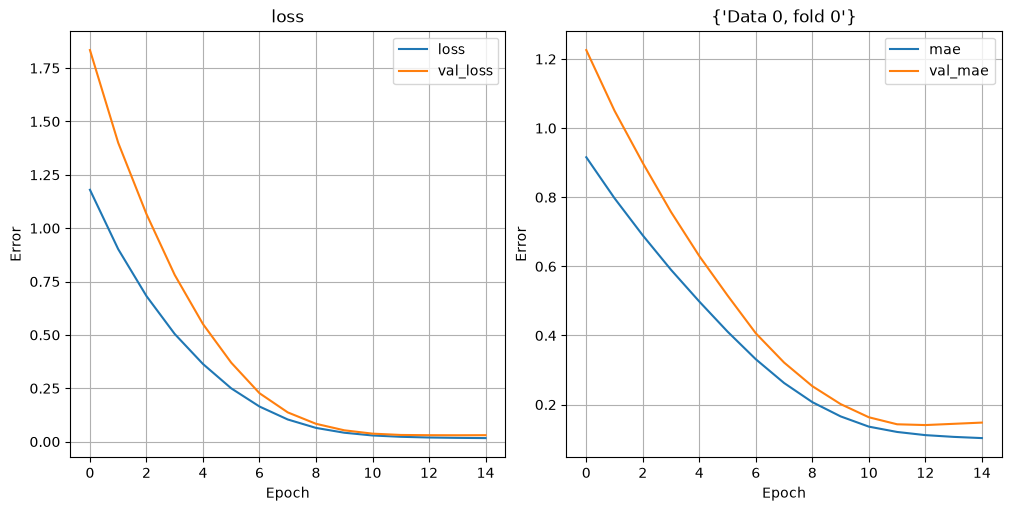

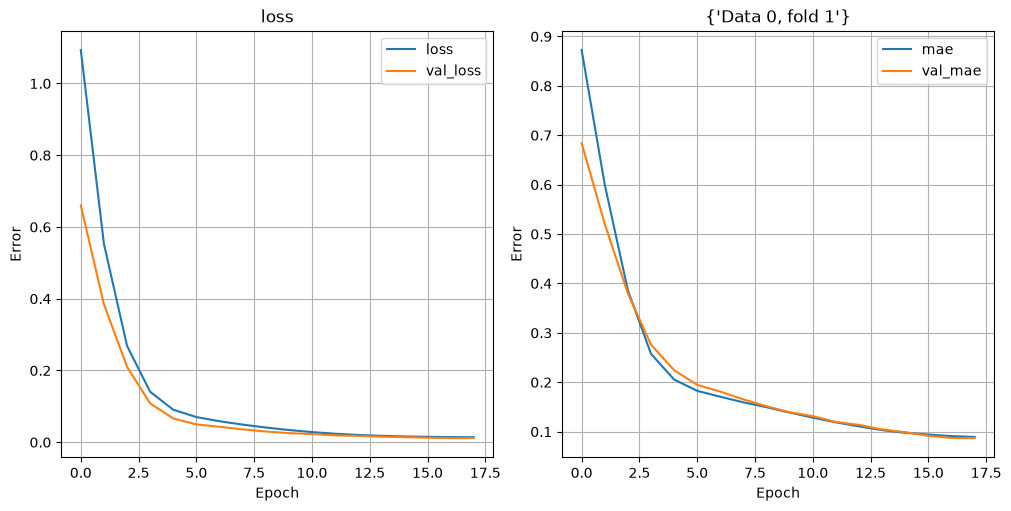

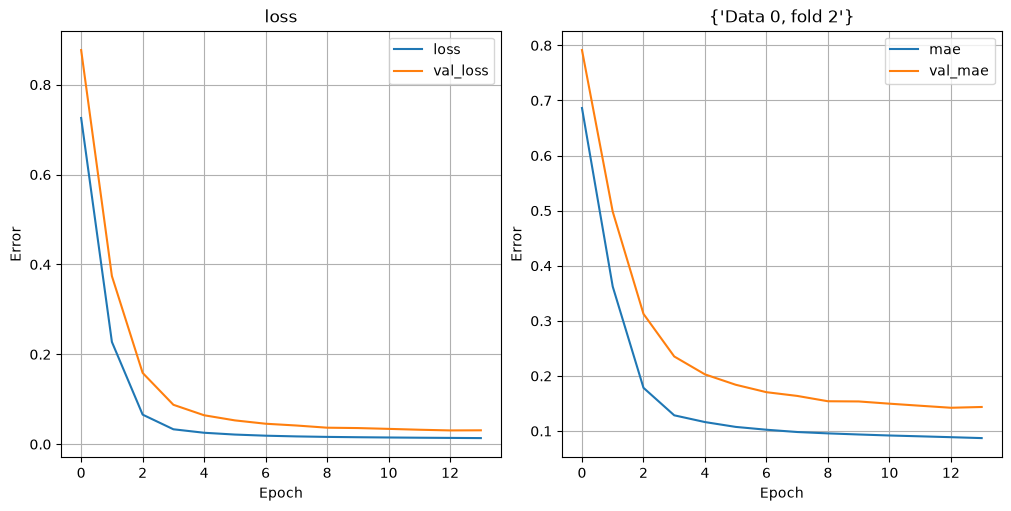

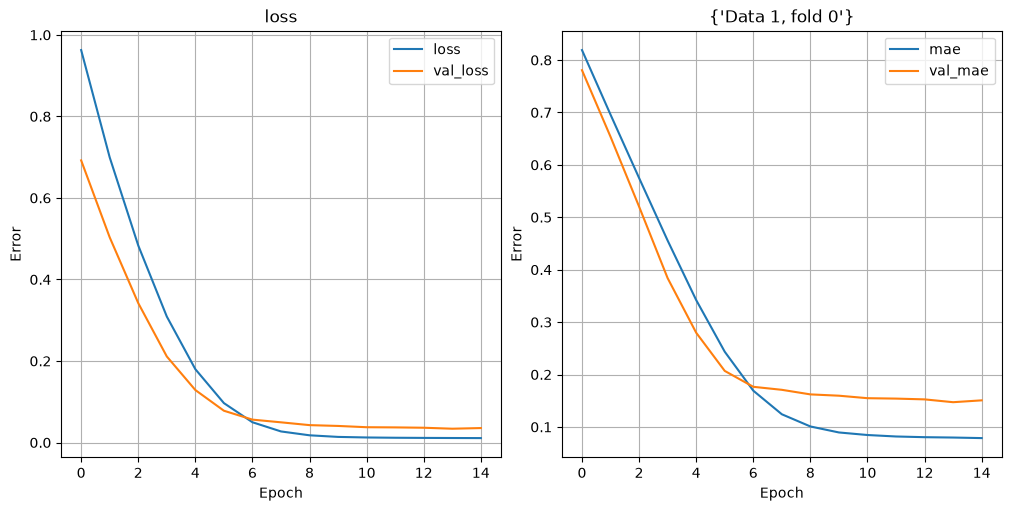

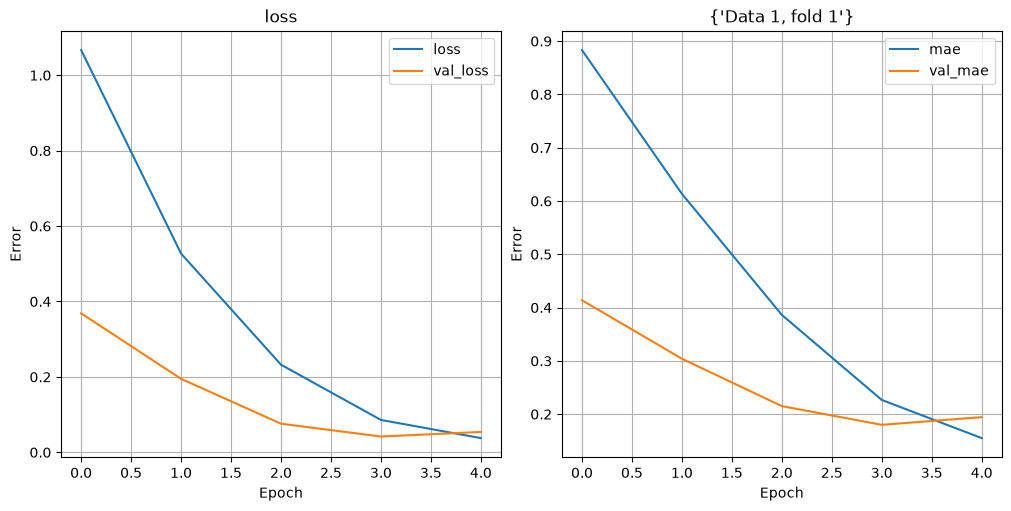

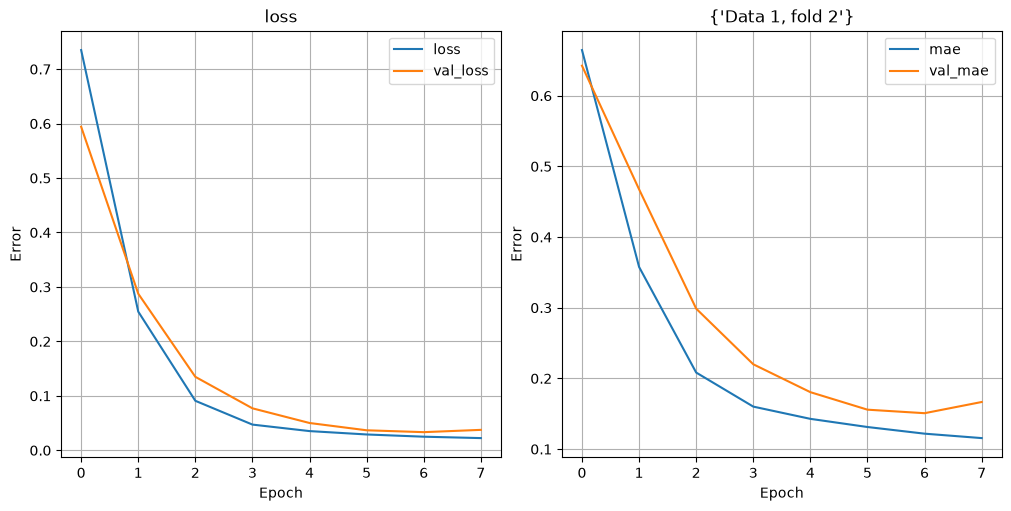

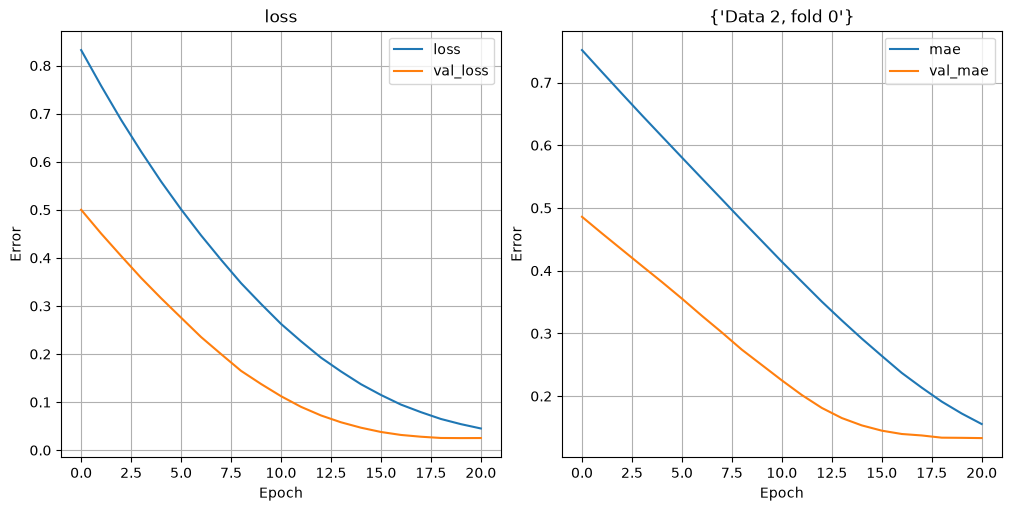

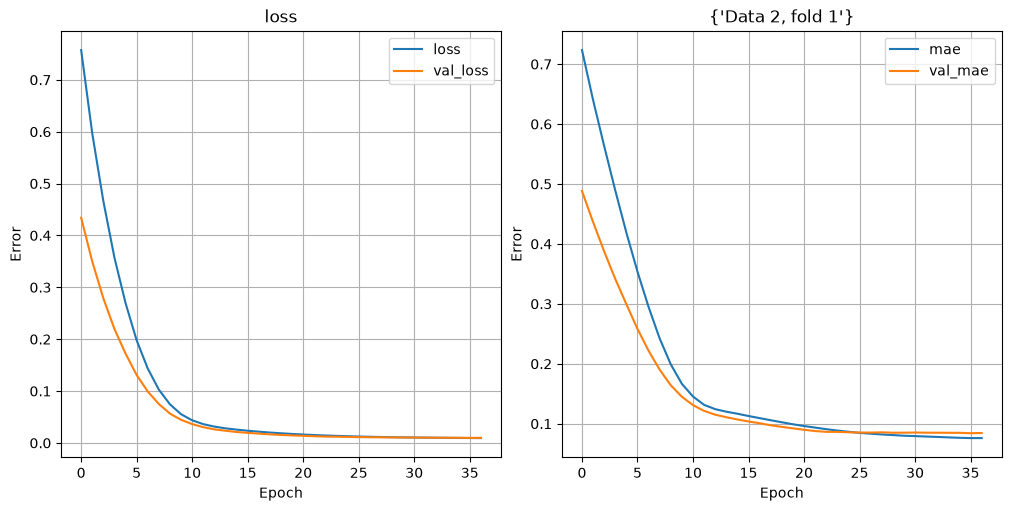

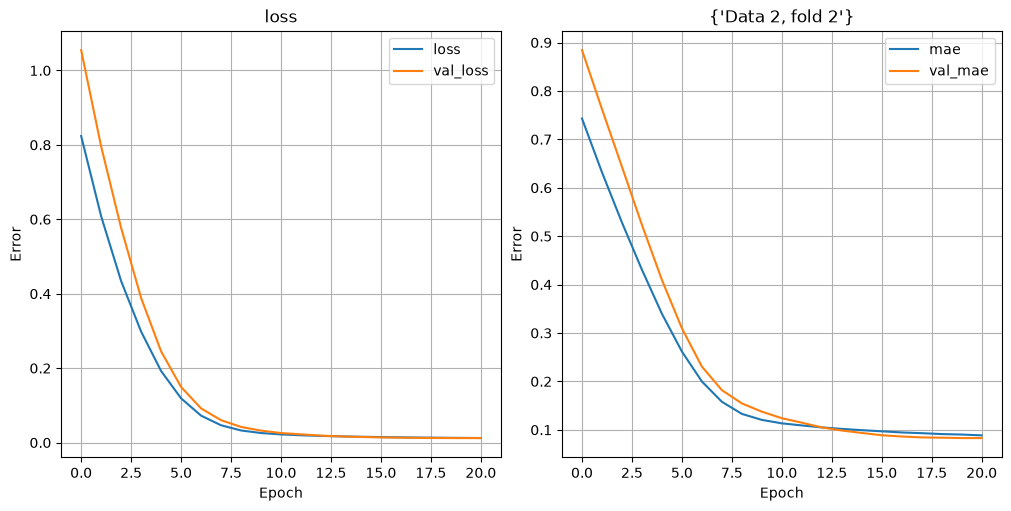

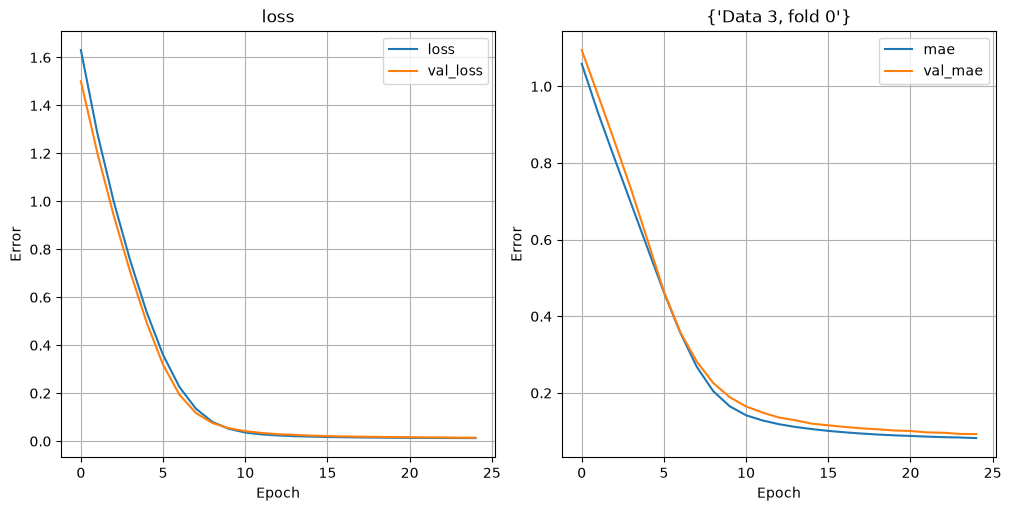

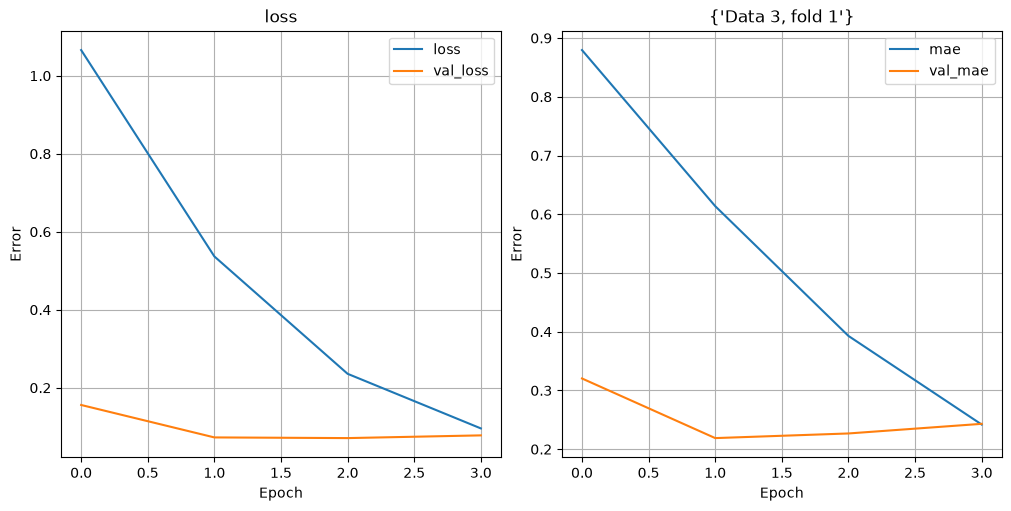

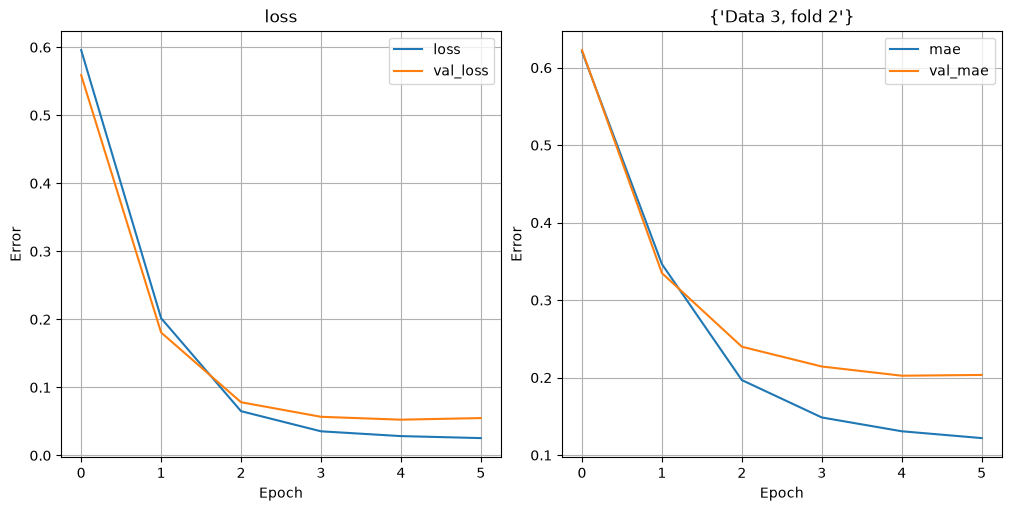

In [70]:
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

# X = X_scaled_all
# y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for data in range(4):
    X = scaled[f"X_scaled_{data}"]
    y = scaled[f"y_scaled_{data}"]
    for i, (train_index, test_index) in enumerate(tscv.split(X)):
        print(f"Fold{data}, {i}:")
        print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
        print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        model = build_nn_model(X_train.shape[1], y_train.shape[1])

        history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=1)
        y_pred = model.predict(X_test, verbose=0)

        evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
        # plot_motors(y_test, y_pred, [-2,2])

        error = mean_squared_error(y_test, y_pred)
        scores.append(error)
        plot_loss_and_mae(history)
        plt.title({f"Data {data}, fold {i}"})

print("MSE scores for each fold:", scores)

Fold3, 0:
  Train: index=0 to 2113 
  Test:  index=2114 to 4222
1

Fold: 0 Results (scaled):
  Overall R2:  0.9524
  Weighted R2: 0.9518
Fold3, 1:
  Train: index=0 to 4222 
  Test:  index=4223 to 6331
1

Fold: 1 Results (scaled):
  Overall R2:  0.9749
  Weighted R2: 0.9752
Fold3, 2:
  Train: index=0 to 6331 
  Test:  index=6332 to 8440
1

Fold: 2 Results (scaled):
  Overall R2:  0.9292
  Weighted R2: 0.9335
Fold3, 3:
  Train: index=0 to 8440 
  Test:  index=8441 to 10549
1

Fold: 3 Results (scaled):
  Overall R2:  0.9575
  Weighted R2: 0.9567
Fold3, 4:
  Train: index=0 to 10549 
  Test:  index=10550 to 12658
1

Fold: 4 Results (scaled):
  Overall R2:  0.9278
  Weighted R2: 0.9249
MSE scores for each fold: [0.04687681794166565, 0.02275720052421093, 0.06239625811576843, 0.04022582247853279, 0.060168396681547165]


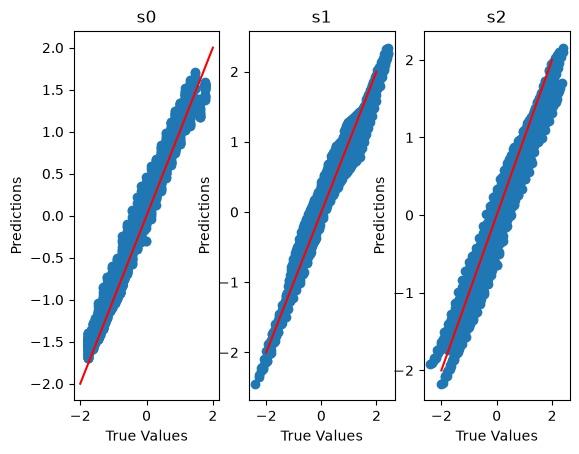

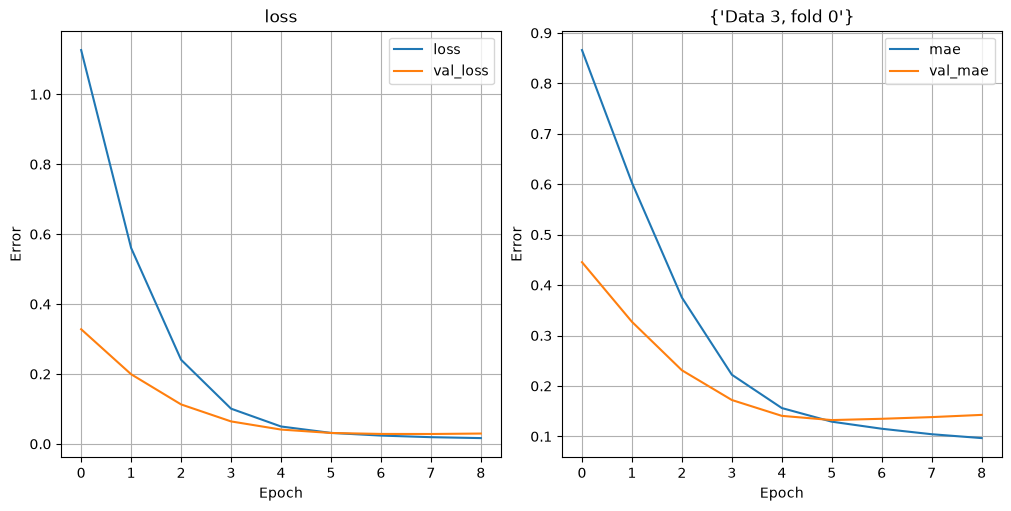

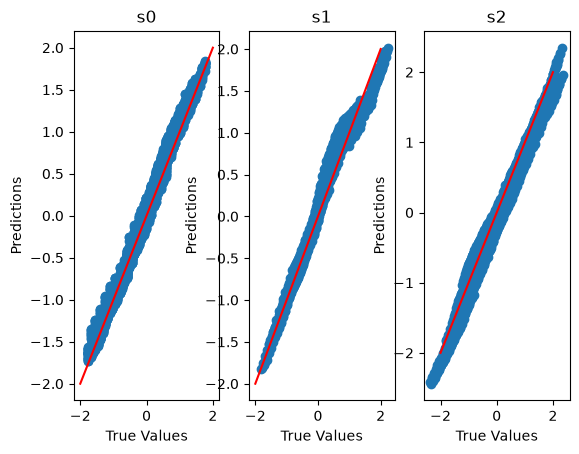

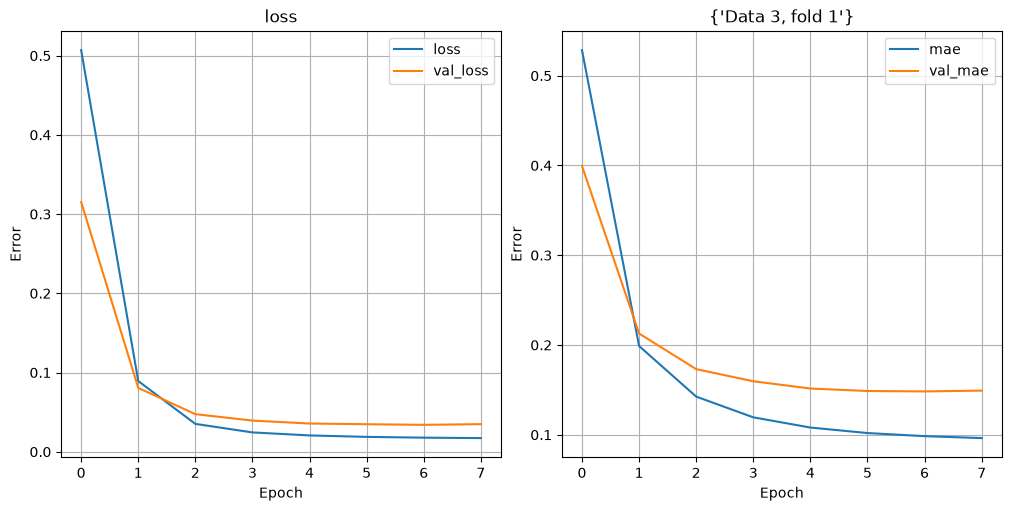

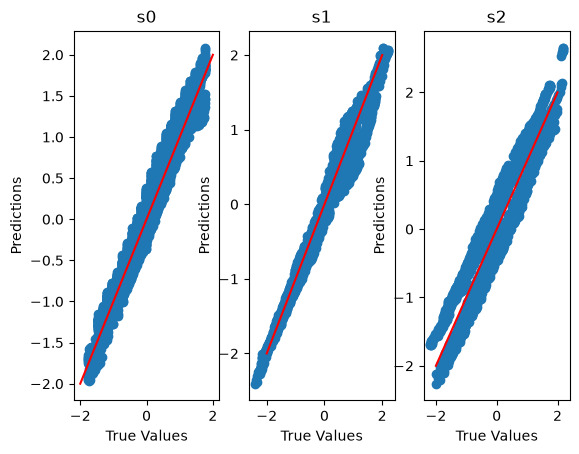

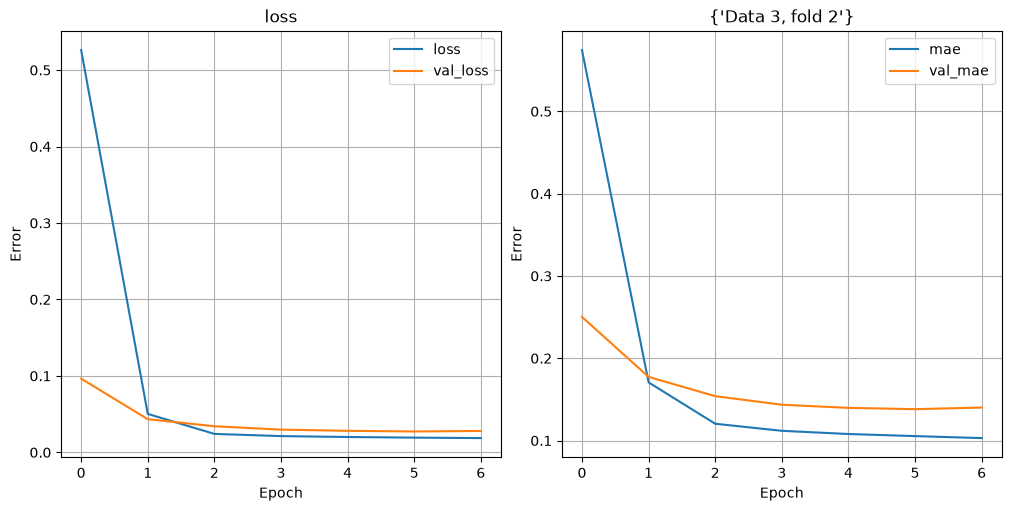

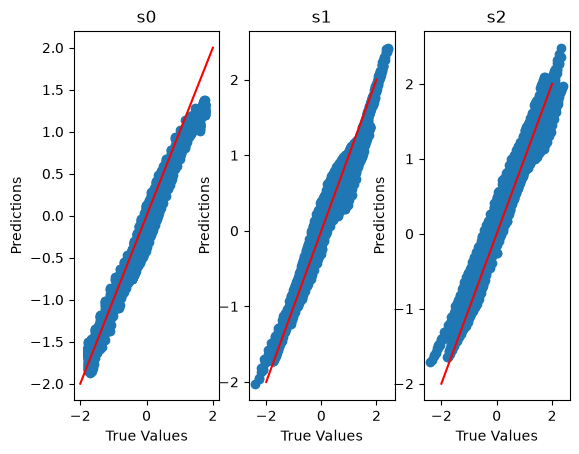

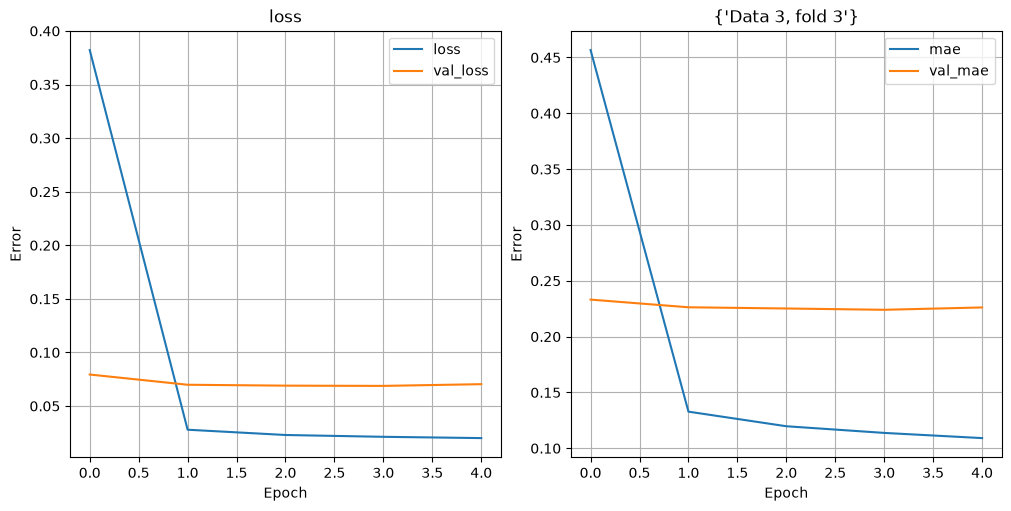

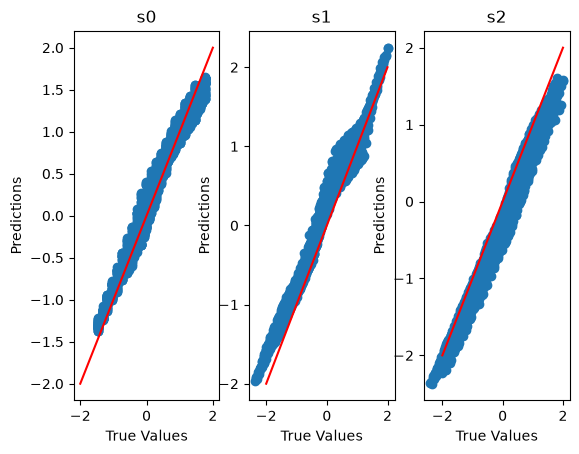

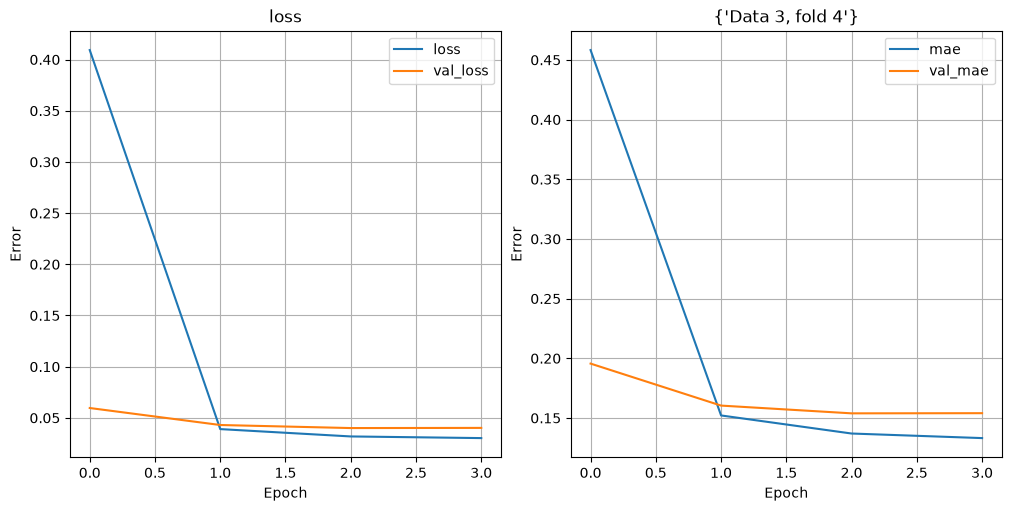

In [75]:
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=5) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold{data}, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_train.shape[1], y_train.shape[1])

    history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    plt.title({f"Data {data}, fold {i}"})

print("MSE scores for each fold:", scores)